In [1]:
import torch
import torchvision
import numpy as np
import pandas as pd
import PIL
import sklearn

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CPU Available:", not torch.cuda.is_available())
print("Device:", "CPU")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
CPU Available: True
Device: CPU


In [1]:
import os

PROJECT_DIR = r"C:\DRISTI\test1A\test1A"

DATASET_DIR = os.path.join(PROJECT_DIR, "Train")

print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Classes:", os.listdir(DATASET_DIR))

Dataset exists: False


FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\DRISTI\\test1A\\test1A\\Train'

In [3]:
from pathlib import Path

dataset_path = Path(DATASET_DIR)

for class_folder in sorted(dataset_path.iterdir()):
    if class_folder.is_dir():
        images = [
            f for f in class_folder.iterdir()
            if f.suffix.lower() in
            [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
        ]

        print(class_folder.name, ":", len(images), "images")

sp-01 : 600 images
sp-02 : 451 images
sp-03 : 460 images
sp-04 : 513 images
sp-05 : 520 images


In [4]:
from PIL import Image

corrupted = []

for class_folder in sorted(dataset_path.iterdir()):
    if class_folder.is_dir():
        for img_path in class_folder.iterdir():
            if img_path.suffix.lower() in [
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            ]:
                try:
                    with Image.open(img_path) as img:
                        img.verify()
                except Exception:
                    corrupted.append(str(img_path))

print("Corrupted images:", len(corrupted))

for image in corrupted:
    print(image)

Corrupted images: 0


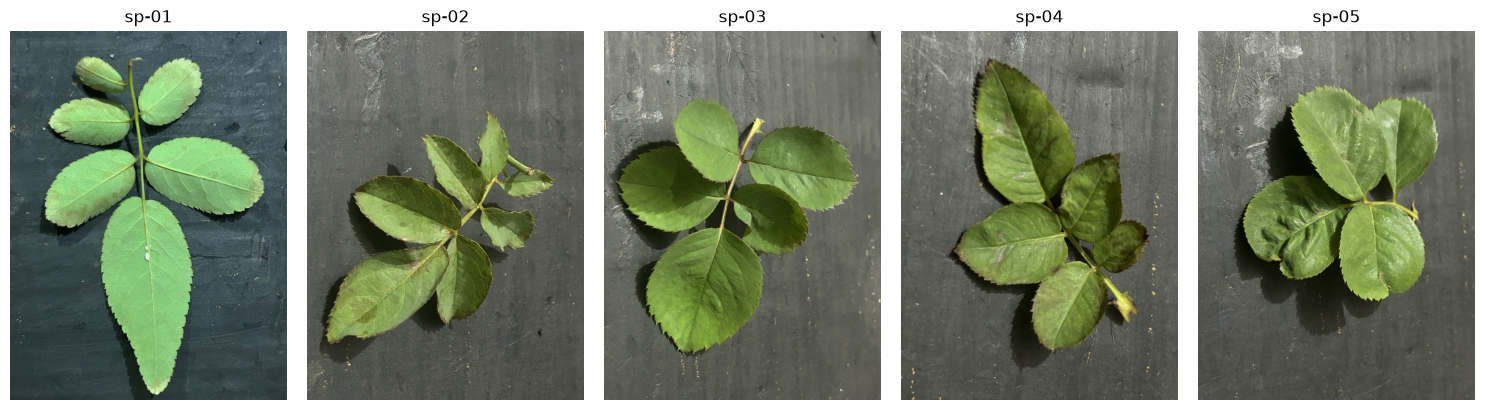

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, class_name in zip(axes, sorted(os.listdir(DATASET_DIR))):
    folder = os.path.join(DATASET_DIR, class_name)

    if os.path.isdir(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        if images:
            img = Image.open(os.path.join(folder, images[0]))
            ax.imshow(img)
            ax.set_title(class_name)

        ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

In [7]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
full_dataset = datasets.ImageFolder(
    DATASET_DIR,
    transform=train_transform
)

class_names = full_dataset.classes

print("Class mapping:", full_dataset.class_to_idx)
print("Total images:", len(full_dataset))

train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=generator
)

# Give validation data its own non-augmented transformation
val_dataset.dataset = datasets.ImageFolder(
    DATASET_DIR,
    transform=val_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Class mapping: {'sp-01': 0, 'sp-02': 1, 'sp-03': 2, 'sp-04': 3, 'sp-05': 4}
Total images: 2544
Training images: 2035
Validation images: 509


In [9]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully")

DataLoaders created successfully


In [10]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])


In [ ]:
#TRAINING 

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.models import ResNet18_Weights

import os
import copy
import time
import matplotlib.pyplot as plt

In [12]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 5

weights = ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Replace original classifier
input_features = model.fc.in_features

model.fc = nn.Linear(
    input_features,
    NUM_CLASSES
)

model = model.to(device)

print(model)
print("Device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\BITHIKA/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:11<00:00, 4.21MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [13]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

print("Feature extractor frozen.")
print("Classification layer trainable.")

Feature extractor frozen.
Classification layer trainable.


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Loss and optimizer configured.")

Loss and optimizer configured.


In [15]:
for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = optim.Adam([
    {"params": model.layer4.parameters(), "lr": 0.0001},
    {"params": model.fc.parameters(), "lr": 0.0005}
])

print("Layer 4 and classifier are trainable.")

Layer 4 and classifier are trainable.


In [16]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

In [18]:
EPOCHS = 15

best_val_accuracy = 0.0

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

best_model_weights = copy.deepcopy(model.state_dict())

In [19]:
for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    # -------------------------
    # TRAINING
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # -------------------------
    # VALIDATION
    # -------------------------

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total

    epoch_val_accuracy = (
        100 * val_correct / val_total
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Train Accuracy: {epoch_train_accuracy:.2f}%")

    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_accuracy:.2f}%")

    # SAVE BEST MODEL

    if epoch_val_accuracy > best_val_accuracy:

        best_val_accuracy = epoch_val_accuracy

        best_model_weights = copy.deepcopy(
            model.state_dict()
        )

        torch.save(
            best_model_weights,
            "resnet18_best.pt"
        )

print("\nTraining completed!")

print(
    "Best validation accuracy:",
    best_val_accuracy
)


Epoch 1/15
Train Loss: 0.6825
Train Accuracy: 74.64%
Validation Loss: 0.2788
Validation Accuracy: 90.77%

Epoch 2/15
Train Loss: 0.2290
Train Accuracy: 92.78%
Validation Loss: 0.2844
Validation Accuracy: 90.57%

Epoch 3/15
Train Loss: 0.1554
Train Accuracy: 94.94%
Validation Loss: 0.1558
Validation Accuracy: 94.70%

Epoch 4/15
Train Loss: 0.1157
Train Accuracy: 95.77%
Validation Loss: 0.1487
Validation Accuracy: 94.50%

Epoch 5/15
Train Loss: 0.1200
Train Accuracy: 95.82%
Validation Loss: 0.1092
Validation Accuracy: 96.27%

Epoch 6/15
Train Loss: 0.0957
Train Accuracy: 96.76%
Validation Loss: 0.1074
Validation Accuracy: 95.28%

Epoch 7/15
Train Loss: 0.0762
Train Accuracy: 97.35%
Validation Loss: 0.1033
Validation Accuracy: 95.68%

Epoch 8/15
Train Loss: 0.0551
Train Accuracy: 98.08%
Validation Loss: 0.0862
Validation Accuracy: 97.25%

Epoch 9/15
Train Loss: 0.0630
Train Accuracy: 98.13%
Validation Loss: 0.0838
Validation Accuracy: 97.25%

Epoch 10/15
Train Loss: 0.0441
Train Accuracy

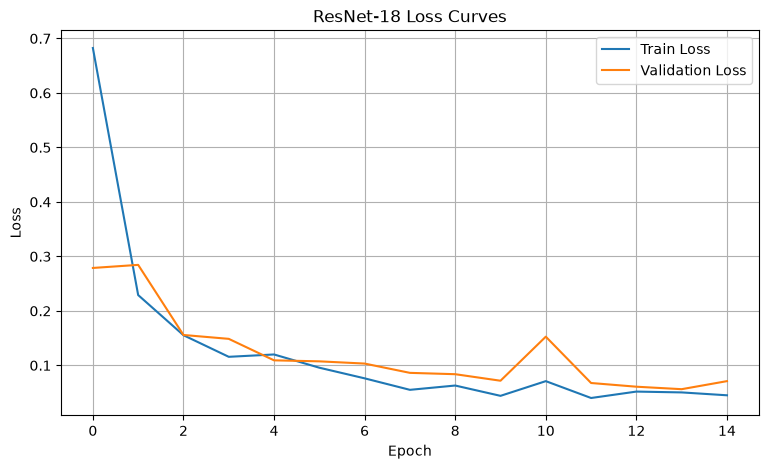

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("ResNet-18 Loss Curves")

plt.legend()
plt.grid()

plt.savefig("loss_curves.png", dpi=300)

plt.show()

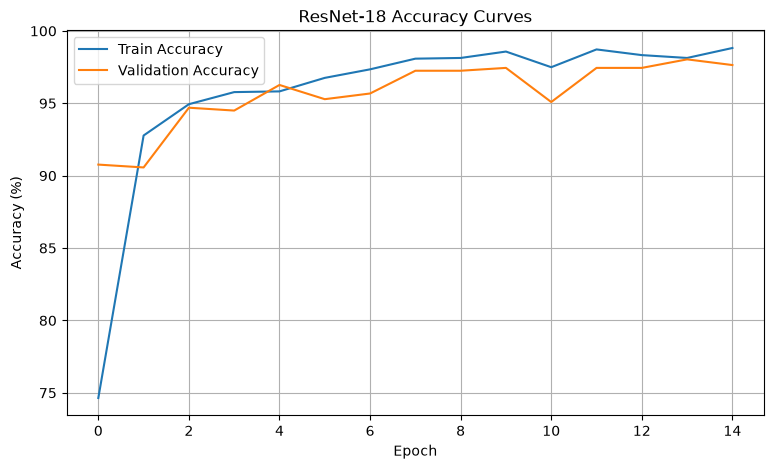

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(train_accuracies, label="Train Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title("ResNet-18 Accuracy Curves")

plt.legend()
plt.grid()

plt.savefig("accuracy_curves.png", dpi=300)

plt.show()

              precision    recall  f1-score   support

       sp-01       1.00      0.98      0.99       116
       sp-02       1.00      0.96      0.98        90
       sp-03       0.99      0.97      0.98        87
       sp-04       0.95      0.99      0.97       101
       sp-05       0.97      1.00      0.98       115

    accuracy                           0.98       509
   macro avg       0.98      0.98      0.98       509
weighted avg       0.98      0.98      0.98       509



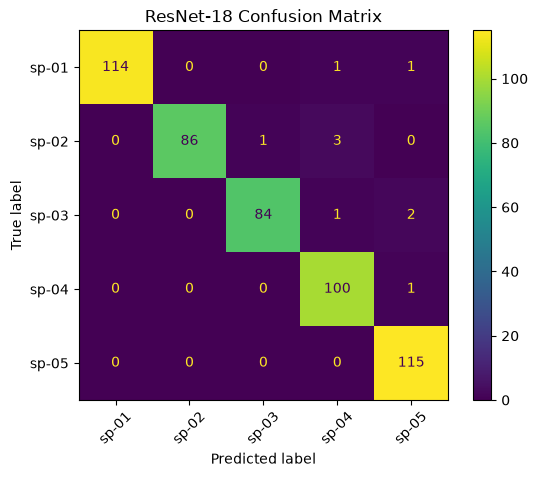

In [22]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

model.load_state_dict(
    torch.load(
        "resnet18_best.pt",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())

        all_predictions.extend(
            predictions.cpu().numpy()
        )

print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)

plt.title("ResNet-18 Confusion Matrix")

plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
model.load_state_dict(
    torch.load(
        "resnet18_best.pt",
        map_location="cpu",
        weights_only=True
    )
)

torch.save(
    model.state_dict(),
    "model.pt"
)

print("Final ResNet-18 model saved.")

Final ResNet-18 model saved.


In [24]:
import os

size_bytes = os.path.getsize("model.pt")

size_mb = size_bytes / (1024 * 1024)

print("Model size:", round(size_mb, 2), "MB")

if size_bytes <= 50_000_000:
    print("PASS: Within 50 MB")
else:
    print("FAIL: Exceeds 50 MB")

Model size: 42.71 MB
PASS: Within 50 MB
